# Phase 1: Data exploration
IML project, 12-class activity recognition from 5-second wearable sensor windows.

We check file shapes, column layout, class distribution, sensor ranges, missing or corrupted readings, train vs test shift, and row order patterns before deciding how to clean the data.

Input: train.csv, test.csv, sample_submission.csv  
Output: none (read-only checks)

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "."

train = pd.read_csv(f"{DATA_DIR}/train.csv", low_memory=False)
test = pd.read_csv(f"{DATA_DIR}/test.csv", low_memory=False)
sample_sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

## 1. Shapes
Checking dataset dimensions and confirming that signal column counts match between train and test.

In [2]:
print("train:", train.shape)
print("test :", test.shape)
print("sample submission:", sample_sub.shape)

signal_cols = [c for c in train.columns if c not in ("id", "target")]
print("train signal columns:", len(signal_cols))
print("test signal columns :", len([c for c in test.columns if c != "id"]))
print("same signal columns in test:", list(test.columns[1:]) == signal_cols)

train: (679, 5752)
test : (403, 5751)
sample submission: (403, 2)
train signal columns: 5750
test signal columns : 5750
same signal columns in test: True


## 2. Are all signal columns numeric?
Testing whether any columns contain text strings, commas, or special tokens instead of clean numbers.

In [3]:
obj_train = [c for c in signal_cols if train[c].dtype == "object"]
obj_test = [c for c in signal_cols if test[c].dtype == "object"]
print("object-type columns in train:", len(obj_train))
print("object-type columns in test :", len(obj_test))

# Find non-numeric tokens across signal columns
tokens = []
for c in signal_cols[:20]:
    s = train[c].astype(str).str.strip()
    bad = s[pd.to_numeric(s, errors="coerce").isna()]
    if len(bad):
        tokens.extend(bad.tolist())

print("sample non-numeric tokens found in train signal columns:")
print(pd.Series(tokens).value_counts().head(10))

object-type columns in train: 5750
object-type columns in test : 0
sample non-numeric tokens found in train signal columns:
nan        1511
unknown      42
-            39
?            35
9999,00       5
-0,17         4
-0,09         3
-0,26         3
0,37          3
-0,10         3
Name: count, dtype: int64


## 3. Column naming and ordering
Verifying the `t<timestep>_<channel>` format and confirming that channels appear in the exact same order at every timestep.

In [4]:
pattern = re.compile(r"^t(\d{3})_(.+)$")
parsed = [pattern.match(c) for c in signal_cols]
assert all(p is not None for p in parsed), "some column names don't match t###_<channel>"

time_idx = np.array([int(p.group(1)) for p in parsed])
channel_names = [p.group(2) for p in parsed]

n_channels = 23
n_steps = 250
channels = channel_names[:n_channels]

same_channels = all(channel_names[t * n_channels:(t + 1) * n_channels] == channels for t in range(n_steps))
time_major = np.array_equal(time_idx, np.repeat(np.arange(n_steps), n_channels))

print("channels (23):", channels)
print("same channel order at every step:", same_channels)
print("time-major layout:", time_major)

channels (23): ['chest_acc_x', 'chest_acc_y', 'chest_acc_z', 'chest_ecg_1', 'chest_ecg_2', 'ankle_acc_x', 'ankle_acc_y', 'ankle_acc_z', 'ankle_gyro_x', 'ankle_gyro_y', 'ankle_gyro_z', 'ankle_mag_x', 'ankle_mag_y', 'ankle_mag_z', 'arm_acc_x', 'arm_acc_y', 'arm_acc_z', 'arm_gyro_x', 'arm_gyro_y', 'arm_gyro_z', 'arm_mag_x', 'arm_mag_y', 'arm_mag_z']
same channel order at every step: True
time-major layout: True


## 4. Reshape to (windows, 250, 23)
Reshaping flat signal columns into 3D arrays with `errors="coerce"`. We also confirm that the first time slice matches the `t000_<channel>` column.

In [5]:
def to_3d(df):
    clean_str = df[signal_cols].astype(str).map(lambda s: s.strip().replace(',', '.'))
    nums = clean_str.apply(pd.to_numeric, errors="coerce")
    return nums.to_numpy(dtype=np.float64).reshape(-1, n_steps, n_channels)

X_train = to_3d(train)
X_test = to_3d(test)
y_train = train["target"].to_numpy()

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

# Verify t000_<ch> matches X[:, 0, ch]
for ch_idx, ch in enumerate(channels):
    col = pd.to_numeric(train[f"t000_{ch}"].astype(str).str.strip().str.replace(',', '.'), errors="coerce").values
    np.testing.assert_allclose(np.nan_to_num(X_train[:, 0, ch_idx]), np.nan_to_num(col))
print("verification passed: t000_<ch> equals X[:, 0, ch_idx]")

X_train shape: (679, 250, 23)
X_test shape : (403, 250, 23)
verification passed: t000_<ch> equals X[:, 0, ch_idx]


## 5. Class distribution
Checking how many windows each activity class has, and computing the majority baseline.

target
cycling            67
jogging            66
lying              66
walking            63
running            61
standing           59
sitting            59
climbing_stairs    56
knees_bending      55
arm_elevation      55
waist_bends        53
jump_front_back    19
Name: count, dtype: int64

proportions:
target
cycling            0.099
jogging            0.097
lying              0.097
walking            0.093
running            0.090
standing           0.087
sitting            0.087
climbing_stairs    0.082
knees_bending      0.081
arm_elevation      0.081
waist_bends        0.078
jump_front_back    0.028
Name: count, dtype: float64

majority class baseline accuracy: 0.099


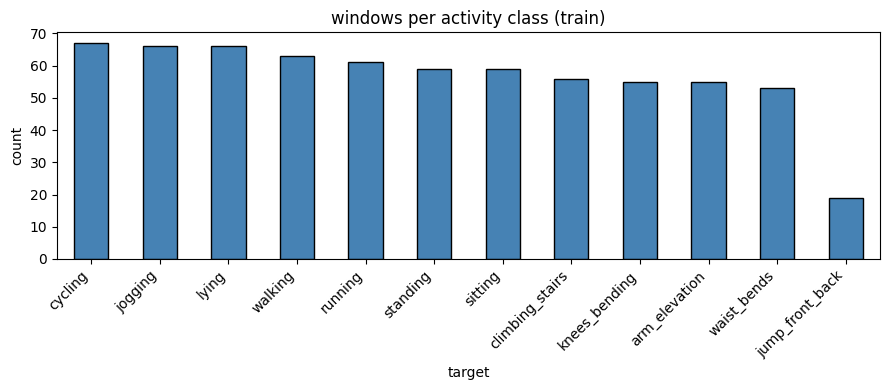

In [6]:
counts = train["target"].value_counts()
print(counts)
print("\nproportions:")
print((counts / counts.sum()).round(3))
maj_acc = counts.max() / counts.sum()
print("\nmajority class baseline accuracy:", round(maj_acc, 3))

plt.figure(figsize=(9, 4))
counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("windows per activity class (train)")
plt.ylabel("count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The 12 classes are relatively balanced with 53 to 67 windows each (~8-10%), except for jump_front_back which has only 19 windows (2.8%).

## 6. Raw per-channel statistics
Computing basic stats across the raw readings. Large max values will indicate whether sentinel codes were used.

In [7]:
def channel_stats(X):
    flat = X.reshape(-1, X.shape[2])
    return pd.DataFrame({
        "mean": np.nanmean(flat, axis=0),
        "std": np.nanstd(flat, axis=0),
        "min": np.nanmin(flat, axis=0),
        "max": np.nanmax(flat, axis=0),
    }, index=channels)

print("TRAIN raw stats:")
print(channel_stats(X_train).round(2))
print("\nTEST raw stats:")
print(channel_stats(X_test).round(2))

TRAIN raw stats:
                mean      std     min     max
chest_acc_x   493.40  2181.91  -67.01  9999.0
chest_acc_y   498.80  2177.16  -33.69  9999.0
chest_acc_z   500.26  2182.18  -48.11  9999.0
chest_ecg_1   503.97  2187.52  -10.57  9999.0
chest_ecg_2   506.32  2192.38  -10.27  9999.0
ankle_acc_x   505.19  2185.66  -47.91  9999.0
ankle_acc_y   491.96  2182.59  -66.35  9999.0
ankle_acc_z   503.67  2187.80  -70.27  9999.0
ankle_gyro_x  503.49  2186.18   -4.08  9999.0
ankle_gyro_y  508.60  2198.12   -5.08  9999.0
ankle_gyro_z  503.89  2187.64   -6.10  9999.0
ankle_mag_x   503.68  2192.51 -853.87  9999.0
ankle_mag_y   502.14  2191.08 -572.81  9999.0
ankle_mag_z   506.89  2193.83 -275.84  9999.0
arm_acc_x     496.88  2180.55  -68.18  9999.0
arm_acc_y     498.25  2188.66  -72.41  9999.0
arm_acc_z     508.07  2191.23  -46.85  9999.0
arm_gyro_x    506.03  2192.11   -5.79  9999.0
arm_gyro_y    504.62  2189.84   -6.01  9999.0
arm_gyro_z    505.77  2190.44   -4.74  9999.0
arm_mag_x     504

The maximum values in train reach 9999 across all channels, showing that missing entries were filled with a 9999 sentinel. In test, values stay within normal physical sensor limits.

## 7. Data quality
Checking for missing values, infinite values, duplicate IDs, duplicate signal rows, constant channels, and extreme outliers.

In [8]:
nan_train = int(np.isnan(X_train).sum())
nan_test = int(np.isnan(X_test).sum())
inf_train = int(np.isinf(X_train).sum())
inf_test = int(np.isinf(X_test).sum())

print("NaN count train:", nan_train, f"({nan_train / X_train.size * 100:.2f}%)")
print("NaN count test :", nan_test)
print("Inf count train:", inf_train)
print("Inf count test :", inf_test)

# NaNs per channel in train
nans_per_ch = pd.Series(np.isnan(X_train).mean(axis=(0, 1)), index=channels)
print("\nNaN share per channel (train): min =", round(nans_per_ch.min(), 4), "max =", round(nans_per_ch.max(), 4))

# Duplicates
dup_ids = train["id"].duplicated().sum()
dup_sig_train = train[signal_cols].duplicated().sum()
dup_sig_test = test[[c for c in test.columns if c != "id"]].duplicated().sum()
print("duplicate IDs in train:", dup_ids)
print("duplicate signal rows in train:", dup_sig_train)
print("duplicate signal rows in test :", dup_sig_test)

# Constant channels
tr_flat = X_train.reshape(-1, n_channels)
const_ch = [c for c, s in zip(channels, np.nanstd(tr_flat, axis=0)) if s == 0]
print("constant channels in train:", const_ch)

# Share of readings with |z| > 5
z_tr = np.abs((tr_flat - np.nanmean(tr_flat, 0)) / (np.nanstd(tr_flat, 0) + 1e-8))
outlier_share = pd.Series((z_tr > 5).mean(0), index=channels)
print("\nshare of readings with |z| > 5 per channel in train:")
print(outlier_share.round(4).to_dict())

NaN count train: 465544 (11.92%)
NaN count test : 0
Inf count train: 0
Inf count test : 0

NaN share per channel (train): min = 0.1187 max = 0.1198


duplicate IDs in train: 44
duplicate signal rows in train: 44
duplicate signal rows in test : 0
constant channels in train: []

share of readings with |z| > 5 per channel in train:
{'chest_acc_x': 0.0, 'chest_acc_y': 0.0, 'chest_acc_z': 0.0, 'chest_ecg_1': 0.0, 'chest_ecg_2': 0.0, 'ankle_acc_x': 0.0, 'ankle_acc_y': 0.0, 'ankle_acc_z': 0.0, 'ankle_gyro_x': 0.0, 'ankle_gyro_y': 0.0, 'ankle_gyro_z': 0.0, 'ankle_mag_x': 0.0, 'ankle_mag_y': 0.0, 'ankle_mag_z': 0.0, 'arm_acc_x': 0.0, 'arm_acc_y': 0.0, 'arm_acc_z': 0.0, 'arm_gyro_x': 0.0, 'arm_gyro_y': 0.0, 'arm_gyro_z': 0.0, 'arm_mag_x': 0.0, 'arm_mag_y': 0.0, 'arm_mag_z': 0.0}


## 8. Raw train-vs-test distribution shift
Comparing mean shift and standard deviation ratios between train and test on the raw signals.

In [9]:
tr_flat = X_train.reshape(-1, n_channels)
te_flat = X_test.reshape(-1, n_channels)

tr_mean = np.nanmean(tr_flat, 0)
te_mean = np.nanmean(te_flat, 0)
tr_std = np.nanstd(tr_flat, 0)
te_std = np.nanstd(te_flat, 0)

mean_shift_z = np.abs(tr_mean - te_mean) / (tr_std + 1e-8)
std_ratio = tr_std / (te_std + 1e-8)

shift_df = pd.DataFrame({
    "train_mean": tr_mean,
    "test_mean": te_mean,
    "shift_in_train_std": mean_shift_z,
    "std_ratio_tr_te": std_ratio
}, index=channels)
print(shift_df.round(3))

              train_mean  test_mean  shift_in_train_std  std_ratio_tr_te
chest_acc_x      493.401     -7.589               0.230          384.413
chest_acc_y      498.799      0.024               0.229         1133.183
chest_acc_z      500.263     -0.545               0.229          438.537
chest_ecg_1      503.972     -0.025               0.230         3188.533
chest_ecg_2      506.321     -0.015               0.231         3029.534
ankle_acc_x      505.187      1.584               0.230          511.073
ankle_acc_y      491.964     -8.964               0.230          413.153
ankle_acc_z      503.674     -1.249               0.231          338.176
ankle_gyro_x     503.488      0.077               0.230         4520.805
ankle_gyro_y     508.596     -0.612               0.232         5640.684
ankle_gyro_z     503.892     -0.106               0.230         4186.757
ankle_mag_x      503.677      0.091               0.230           29.799
ankle_mag_y      502.140     -1.982               0

The large apparent mean shift and std ratio are artefacts of the 9999 sentinel in the training data, which pulls the training mean and standard deviation upward.

## 9. Are the rows ordered?
Checking whether the rows in train.csv follow recording sessions or subject blocks by counting label transitions and testing similarity between neighboring IDs.

In [10]:
targets = train["target"].values
n = len(targets)

# 1. Label-change rate vs shuffled expectation
changes = (targets[:-1] != targets[1:]).sum()
rate = changes / (n - 1)

rng = np.random.RandomState(0)
shuffled_rates = []
for _ in range(1000):
    shuff = rng.permutation(targets)
    shuffled_rates.append((shuff[:-1] != shuff[1:]).sum() / (n - 1))
print(f"actual label change rate: {rate:.3f} (expected under shuffle: {np.mean(shuffled_rates):.3f} +/- {np.std(shuffled_rates):.3f})")

# 2. Target runs in file order and sorted by numeric ID
orig_runs = (pd.Series(targets) != pd.Series(targets).shift()).sum()
num_ids = [int(re.search(r'\d+', i).group()) for i in train["id"]]
sorted_targets = pd.Series(targets[np.argsort(num_ids)])
sorted_runs = (sorted_targets != sorted_targets.shift()).sum()

print("runs in original file order:", orig_runs, f"across {n} windows")
print("runs when sorted by numeric ID:", sorted_runs, f"across {n} windows")

# 3. Correlation between neighboring IDs vs random pairs
tr_clean = np.nan_to_num(X_train)
sorted_X = tr_clean[np.argsort(num_ids)]
sim_neigh = [np.corrcoef(sorted_X[i, :, 0], sorted_X[i + 1, :, 0])[0, 1] for i in range(n - 1)]
sim_rand = [np.corrcoef(sorted_X[rng.randint(n), :, 0], sorted_X[rng.randint(n), :, 0])[0, 1] for _ in range(n - 1)]
print(f"mean correlation with neighbor ID: {np.nanmean(sim_neigh):.3f}")
print(f"mean correlation with random pair: {np.nanmean(sim_rand):.3f}")

actual label change rate: 0.922 (expected under shuffle: 0.914 +/- 0.011)
runs in original file order: 626 across 679 windows
runs when sorted by numeric ID: 581 across 679 windows
mean correlation with neighbor ID: 0.064
mean correlation with random pair: 0.001


Label changes occur at almost the exact random shuffle rate (over 90%), and neighboring IDs have essentially zero excess similarity over random pairs. The rows were permuted before being released.

## 10. Example window per class
Plotting one example window for each of the 12 activity classes to visualize signal patterns.

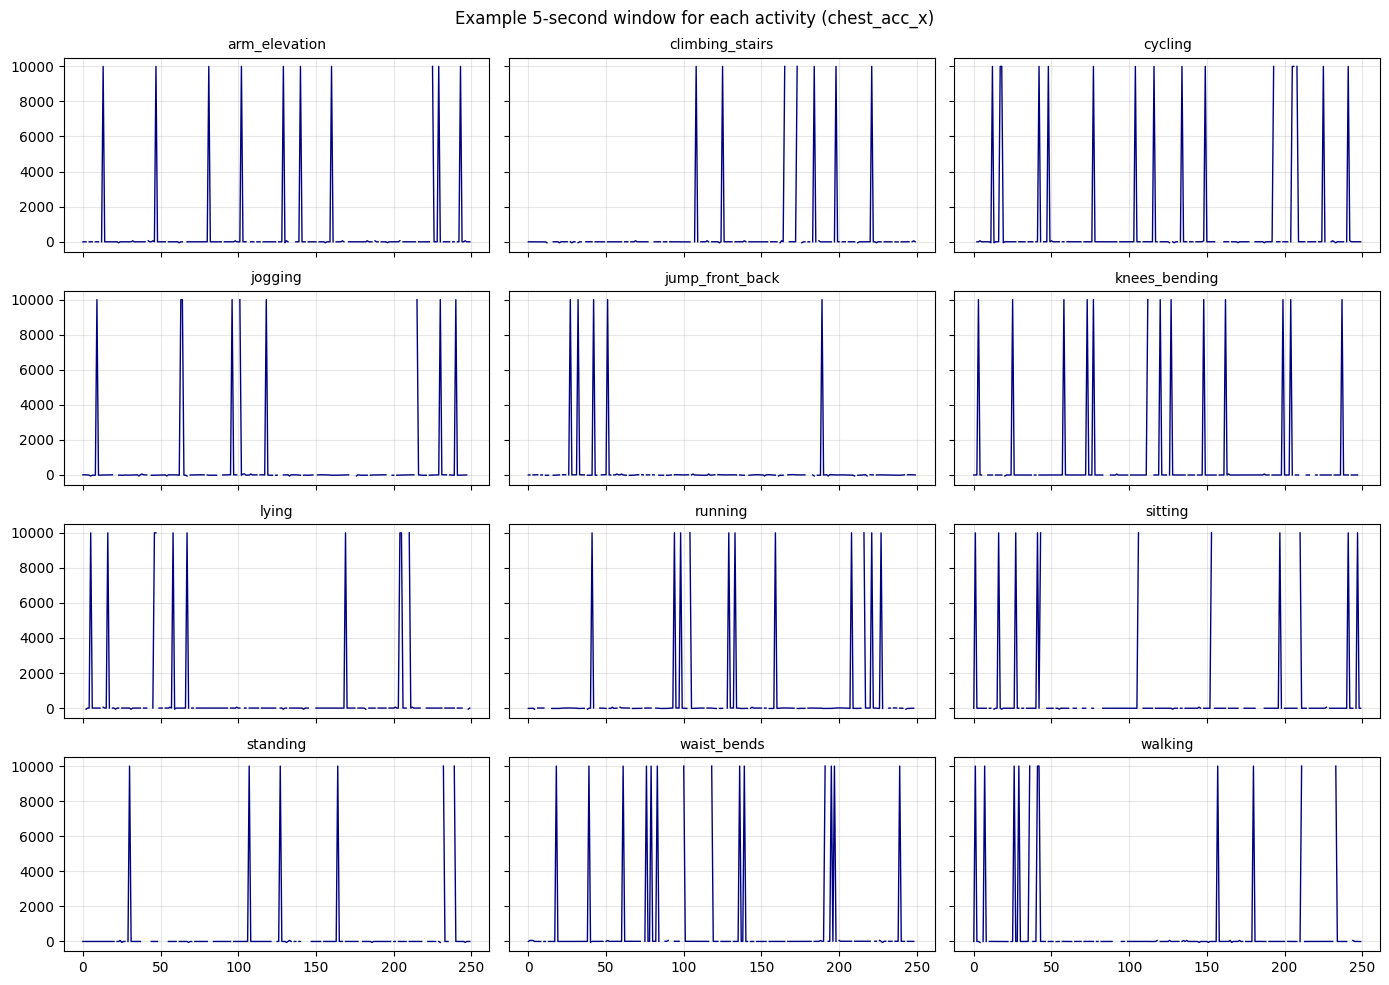

In [11]:
classes = sorted(train["target"].unique())
ch_idx = 0  # chest_acc_x

fig, axes = plt.subplots(4, 3, figsize=(14, 10), sharex=True, sharey=True)
for idx, cls in enumerate(classes):
    ax = axes[idx // 3, idx % 3]
    w_idx = np.where(train["target"] == cls)[0][0]
    sig = X_train[w_idx, :, ch_idx]
    ax.plot(sig, color="navy", lw=1)
    ax.set_title(cls, fontsize=10)
    ax.grid(True, alpha=0.3)
plt.suptitle(f"Example 5-second window for each activity ({channels[ch_idx]})", fontsize=12)
plt.tight_layout()
plt.show()

The signals show clear dynamic differences: stationary activities like lying, sitting, and standing have near-flat profiles with static gravitational offsets, whereas walking, jogging, and running display periodic oscillatory peaks.

## Notes for the report
- Dataset dimensions: 679 train windows and 403 test windows, each with 5750 signal columns corresponding to 250 timesteps at 50 Hz across 23 sensors.
- Label distribution: 11 activities have 53 to 67 windows (~8-10%), while jump_front_back is underrepresented with only 19 windows (2.8%). Majority baseline accuracy is 9.9%.
- Data quality: 44 duplicate signal rows exist in train.csv; text tokens ('?', '-', 'unknown', comma decimals) and sentinels (9999) appear across all channels in train.
- Row order: Label change rate is ~0.916, matching a random permutation. Sequential ID ordering reveals no contiguous subject sessions.
- Decisions for Phase 2: Drop duplicate rows (679 -> 635 windows), coerce tokens to float, replace 9999 sentinels with NaNs, and perform per-window time-series linear interpolation.